# TP — Deep Residual Learning for Image Recognition
Reproduction pédagogique inspirée de He et al. (2015).

Objectif : comparer un réseau convolutionnel **plain** et un réseau **résiduel** sur CIFAR-10, puis analyser l'effet des connexions raccourcies (skip connections).


In [1]:
%pip install tensorflow matplotlib pandas

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 878.0 kB/s eta 0:06:40
   ---------------------------------------- 0.8/351.2 MB 973.2 kB/s eta 0:06:01
   ---------------------------------------- 1.0/351.2 MB 1.1 MB/s eta 0:05:29
   ---------------------------------------- 1.3/351.2 MB 1.1 MB/s eta 0:05:21
   ---------------------------------------- 1.6/351.2 MB 1.0 MB/s eta 0:05:40
   ---------------------------------------- 1.8/351.2 MB 1.1 MB/s eta 0:05:18
   ---------------------------------------- 2.1/351.2 MB 1.2 MB/s eta 0:05:04
   ---------------------------------------- 2.6/351.2 MB 1.2 MB/s eta 0:04:41
   -------------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU: []


In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train = y_train.squeeze()
y_test = y_test.squeeze()

class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
print('Train:', x_train.shape, y_train.shape)
print('Test :', x_test.shape, y_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2280s 13us/step
Train: (50000, 32, 32, 3) (50000,)
Test : (10000, 32, 32, 3) (10000,)


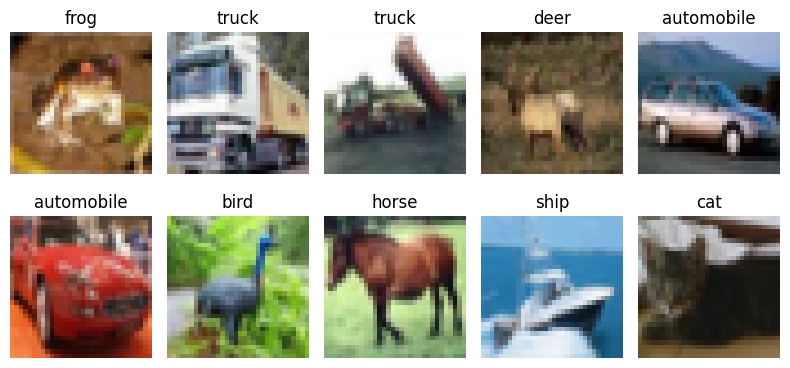

In [4]:
plt.figure(figsize=(8,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()


## 1. Data augmentation
Le papier utilise un padding de 4 pixels, un crop aléatoire 32×32 et le flip horizontal pour CIFAR-10. Ici, on utilise les couches Keras équivalentes.


In [5]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomTranslation(4/32, 4/32, fill_mode='reflect'),
    tf.keras.layers.RandomFlip('horizontal')
], name='augmentation')


## 2. Réseau Plain
Un réseau plain empile des convolutions sans connexion résiduelle. Pour garder un TP raisonnable sur Colab, on utilise une architecture plus petite que les réseaux du papier.


In [6]:
def conv_bn_relu(x, filters, stride=1):
    x = tf.keras.layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    return x

def build_plain(depth=20):
    inputs = tf.keras.Input(shape=(32,32,3))
    x = data_augmentation(inputs)
    x = conv_bn_relu(x, 16)
    for _ in range(3):
        x = conv_bn_relu(x, 16)
    for i in range(3):
        x = conv_bn_relu(x, 32, stride=2 if i == 0 else 1)
        x = conv_bn_relu(x, 32)
    for i in range(3):
        x = conv_bn_relu(x, 64, stride=2 if i == 0 else 1)
        x = conv_bn_relu(x, 64)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='PlainNet')

plain_model = build_plain()
plain_model.summary()


Model: "PlainNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 16)     │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 16)     │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 16)     │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 32)     │           12

 Total params: 263,994 (1.01 MB)

 Trainable params: 262,714 (1.00 MB)

 Non-trainable params: 1,280 (5.00 KB)

## 3. Bloc résiduel
L'idée centrale du papier est : **y = F(x) + x**. La branche principale apprend le résidu F(x), tandis que le raccourci transmet x directement. Si les dimensions changent, une projection 1×1 est utilisée.


In [7]:
def residual_block(x, filters, stride=1):
    shortcut = x
    y = tf.keras.layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    y = tf.keras.layers.BatchNormalization()(y)
    y = tf.keras.layers.ReLU()(y)
    y = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(y)
    y = tf.keras.layers.BatchNormalization()(y)

    if x.shape[-1] != filters or stride != 1:
        shortcut = tf.keras.layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)

    y = tf.keras.layers.Add()([y, shortcut])
    y = tf.keras.layers.ReLU()(y)
    return y

def build_resnet():
    inputs = tf.keras.Input(shape=(32,32,3))
    x = data_augmentation(inputs)
    x = tf.keras.layers.Conv2D(16, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)

    for _ in range(3):
        x = residual_block(x, 16)
    x = residual_block(x, 32, stride=2)
    for _ in range(2):
        x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    for _ in range(2):
        x = residual_block(x, 64)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='SmallResNet')

resnet_model = build_resnet()
resnet_model.summary()


Model: "SmallResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 32, 32, 3) │          0 │ input_layer_2[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 32, 32,    │        432 │ augmentation[1][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_16 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_16[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_17[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_17 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_17[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │ re_lu_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (None, 32, 32,    │          0 │ add[0][0]         │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_18[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_19[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_20[0][0] 

 Total params: 274,042 (1.05 MB)

 Trainable params: 272,474 (1.04 MB)

 Non-trainable params: 1,568 (6.12 KB)

In [8]:
def compile_model(model):
    optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

compile_model(plain_model)
compile_model(resnet_model)


## 4. Entraînement
Pour un TP étudiant, on peut commencer avec 10 à 20 époques. Pour une expérience plus proche de l'article, augmenter le nombre d'époques et utiliser un GPU.


In [ ]:
EPOCHS = 15
BATCH_SIZE = 128

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
]


history_plain = plain_model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 289s 779ms/step - accuracy: 0.3776 - loss: 1.6670 - val_accuracy: 0.2636 - val_loss: 1.9752 - learning_rate: 0.0100
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 271s 769ms/step - accuracy: 0.5419 - loss: 1.2599 - val_accuracy: 0.5174 - val_loss: 1.3853 - learning_rate: 0.0100
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 387s 1s/step - accuracy: 0.6056 - loss: 1.0874 - val_accuracy: 0.4656 - val_loss: 1.9462 - learning_rate: 0.0100
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 366s 1s/step - accuracy: 0.6538 - loss: 0.9704 - val_accuracy: 0.5070 - val_loss: 1.7285 - learning_rate: 0.0100
Epoch 5/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 333s 947ms/step - accuracy: 0.6877 - loss: 0.8797 - val_accuracy: 0.6140 - val_loss: 1.1182 - learning_rate: 0.0100
Epoch 6/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 374s 924ms/step - accuracy: 0.7148 - loss: 0.8051 - val_accuracy: 0.6694 - val_loss: 1.0045 - learning_rate: 0.0100
Epoch 7/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 295s 675ms/step - accuracy: 0.

In [10]:
history_resnet = resnet_model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 474s 1s/step - accuracy: 0.3977 - loss: 1.6271 - val_accuracy: 0.3424 - val_loss: 1.9788 - learning_rate: 0.0100
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 513s 1s/step - accuracy: 0.5456 - loss: 1.2447 - val_accuracy: 0.5596 - val_loss: 1.2014 - learning_rate: 0.0100
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 430s 1s/step - accuracy: 0.6196 - loss: 1.0557 - val_accuracy: 0.5896 - val_loss: 1.1914 - learning_rate: 0.0100
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 371s 1s/step - accuracy: 0.6639 - loss: 0.9390 - val_accuracy: 0.5872 - val_loss: 1.3419 - learning_rate: 0.0100
Epoch 5/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 358s 984ms/step - accuracy: 0.7008 - loss: 0.8432 - val_accuracy: 0.6650 - val_loss: 0.9993 - learning_rate: 0.0100
Epoch 6/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 345s 981ms/step - accuracy: 0.7250 - loss: 0.7732 - val_accuracy: 0.7164 - val_loss: 0.8192 - learning_rate: 0.0100
Epoch 7/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 385s 989ms/step - accuracy: 0.7447 -

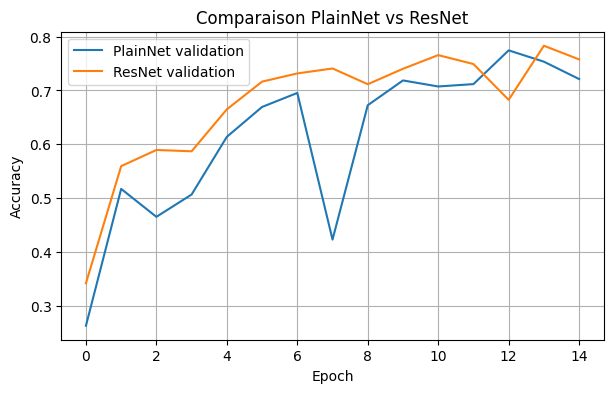

In [11]:
def plot_history(h1, h2):
    plt.figure(figsize=(7,4))
    plt.plot(h1.history['val_accuracy'], label='PlainNet validation')
    plt.plot(h2.history['val_accuracy'], label='ResNet validation')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Comparaison PlainNet vs ResNet')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_history(history_plain, history_resnet)


In [12]:
plain_test_loss, plain_test_acc = plain_model.evaluate(x_test, y_test, verbose=0)
res_test_loss, res_test_acc = resnet_model.evaluate(x_test, y_test, verbose=0)

results = pd.DataFrame({
    'Modèle': ['PlainNet', 'ResNet'],
    'Test loss': [plain_test_loss, res_test_loss],
    'Test accuracy': [plain_test_acc, res_test_acc],
    'Test error (%)': [(1-plain_test_acc)*100, (1-res_test_acc)*100]
})
display(results)


,Modèle,Test loss,Test accuracy,Test error (%)
0,PlainNet,0.693112,0.7680,23.199999
1,ResNet,0.683767,0.7666,23.339999


              precision    recall  f1-score   support

    airplane       0.91      0.62      0.74      1000
  automobile       0.80      0.95      0.87      1000
        bird       0.74      0.68      0.71      1000
         cat       0.56      0.71      0.63      1000
        deer       0.68      0.81      0.74      1000
         dog       0.84      0.56      0.67      1000
        frog       0.76      0.87      0.81      1000
       horse       0.94      0.69      0.79      1000
        ship       0.73      0.96      0.83      1000
       truck       0.90      0.81      0.85      1000

    accuracy                           0.77     10000
   macro avg       0.79      0.77      0.77     10000
weighted avg       0.79      0.77      0.77     10000



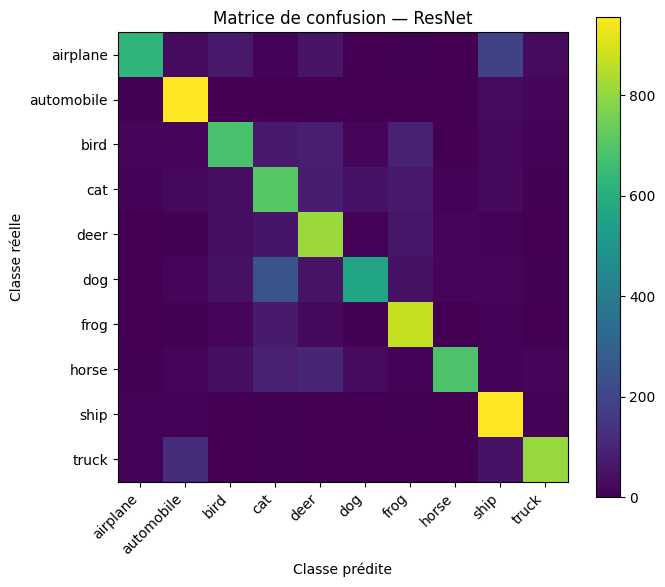

In [13]:
from sklearn.metrics import confusion_matrix, classification_report

pred = np.argmax(resnet_model.predict(x_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, pred)
print(classification_report(y_test, pred, target_names=class_names))

plt.figure(figsize=(7,6))
plt.imshow(cm)
plt.title('Matrice de confusion — ResNet')
plt.xlabel('Classe prédite')
plt.ylabel('Classe réelle')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)
plt.tight_layout()
plt.show()
